In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans


In [3]:
df=pd.read_csv('data.csv', encoding='latin-1')
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [4]:
df.describe()


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


**we should transform the data type of each column**



**InvoiceDate  to date type** 



**CustomerID to integer**


In [6]:
df 

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

In [10]:
#check if there is a letter in invoiceNO column
df[df['InvoiceNo'].str.contains('[a-zA-Z]')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,12/1/2010 9:41,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,12/1/2010 9:49,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,12/1/2010 10:24,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,12/1/2010 10:24,0.29,17548.0,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,12/9/2011 9:57,0.83,14397.0,United Kingdom
541541,C581499,M,Manual,-1,12/9/2011 10:28,224.69,15498.0,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,12/9/2011 11:57,10.95,15311.0,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,12/9/2011 11:58,1.25,17315.0,United Kingdom


**this column is in right form**

In [11]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [12]:
df.info()

<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  str           
 1   StockCode    536641 non-null  str           
 2   Description  535187 non-null  str           
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[us]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      536641 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 63.2 MB


**transform the id customer colum to string and fill the nan  values with "Geust" to make guest vs registered revenue. analysis**

In [13]:
df["CustomerID"] = df["CustomerID"].apply(
    lambda x: "Guest" if pd.isna(x) else str(int(x))
)

In [14]:
df['Description']=df['Description'].fillna('No description')

In [15]:
df.info()

<class 'pandas.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  str           
 1   StockCode    536641 non-null  str           
 2   Description  536641 non-null  str           
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[us]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   536641 non-null  str           
 7   Country      536641 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(5)
memory usage: 65.7 MB


In [16]:
df[df['Quantity'] < 0]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315,United Kingdom


In [17]:
#display the rows that starts with C in innoviceNO
df[df['InvoiceNo'].str.startswith('C')]



,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397,United Kingdom
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498,United Kingdom
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311,United Kingdom
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315,United Kingdom


**we notice that when the quantity is negative the innoviceNo starts with C wich stads for canceled so we need to drop these rows**

In [18]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [19]:
df = df[df["Quantity"] > 0]

In [20]:
df = df[df["UnitPrice"] > 0]

In [21]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France


In [22]:
df.describe()

,Quantity,InvoiceDate,UnitPrice
count,524878.000000,524878,524878.000000
mean,10.616600,2011-07-04 15:30:16.317049,3.922573
min,1.000000,2010-12-01 08:26:00,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000
50%,4.000000,2011-07-20 11:22:00,2.080000
75%,11.000000,2011-10-19 11:41:00,4.130000
max,80995.000000,2011-12-09 12:50:00,13541.330000
std,156.280031,NaN,36.093028


In [23]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

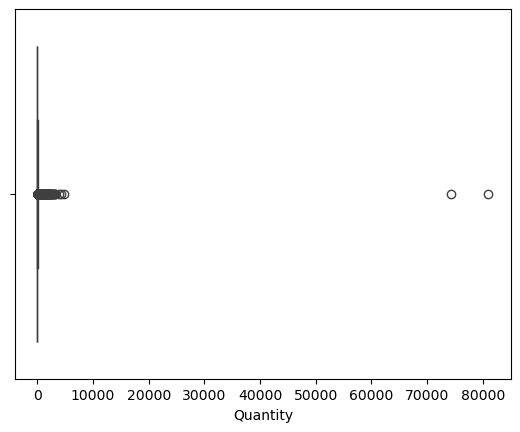

In [24]:
#boxplot of quantity
plt.figure()
sns.boxplot(x=df["Quantity"])
plt.show()



**WE notice there is 2 outliers so the best practise is to drop them manualy withou using iqr method**

In [25]:
df[df["Quantity"] > 50000]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,77183.6
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.6


In [26]:
df=df[df["Quantity"] <= 50000]

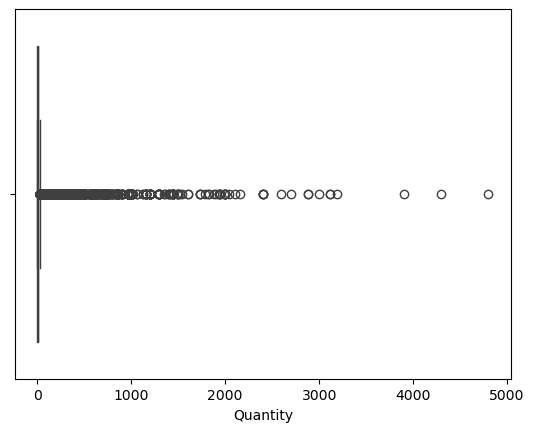

In [27]:
plt.figure()
sns.boxplot(x=df["Quantity"])
plt.show()

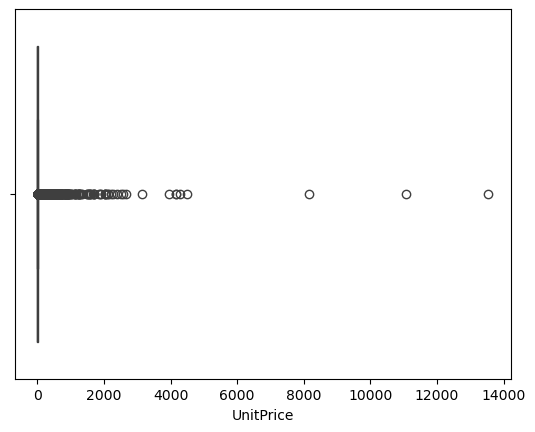

In [28]:
plt.figure()
sns.boxplot(x=df["UnitPrice"])
plt.show()

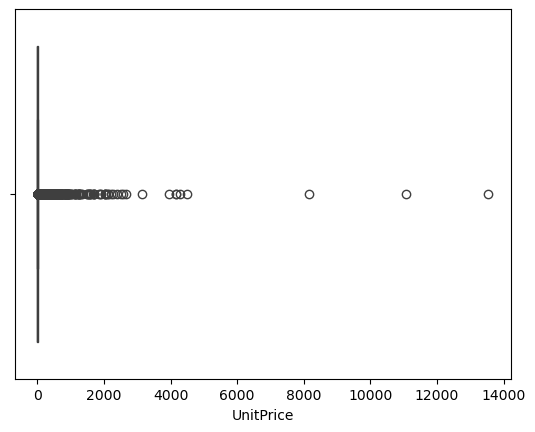

In [29]:
plt.figure()
sns.boxplot(x=df["UnitPrice"])
plt.show()

In [30]:
df.sort_values(by="UnitPrice", ascending=False).head(20)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
15017,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,Guest,United Kingdom,13541.33
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,Guest,United Kingdom,11062.06
173382,551697,POST,POSTAGE,1,2011-05-03 13:46:00,8142.75,16029,United Kingdom,8142.75
297723,562955,DOT,DOTCOM POSTAGE,1,2011-08-11 10:14:00,4505.17,Guest,United Kingdom,4505.17
268028,560373,M,Manual,1,2011-07-18 12:30:00,4287.63,Guest,United Kingdom,4287.63
422376,573080,M,Manual,1,2011-10-27 14:20:00,4161.06,12536,France,4161.06
422351,573077,M,Manual,1,2011-10-27 14:13:00,4161.06,12536,France,4161.06
406406,571751,M,Manual,1,2011-10-19 11:18:00,3949.32,12744,Singapore,3949.32
374542,569382,M,Manual,1,2011-10-03 16:44:00,3155.95,15502,United Kingdom,3155.95
347948,567353,M,Manual,1,2011-09-19 16:14:00,2653.95,Guest,Hong Kong,2653.95


**we notice the descreption of the most expensive are not real product and the price is 130.00 so we will hundle  bouth of descreption and the unit price outlier**

In [31]:
df[df['Description'].isin({'POSTAGE','Manual'})]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583,France,54.00
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791,Netherlands,15.00
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662,Germany,18.00
2239,536569,M,Manual,1,2010-12-01 15:35:00,1.25,16274,United Kingdom,1.25
2250,536569,M,Manual,1,2010-12-01 15:35:00,18.95,16274,United Kingdom,18.95
...,...,...,...,...,...,...,...,...,...
541198,581493,POST,POSTAGE,1,2011-12-09 10:10:00,15.00,12423,Belgium,15.00
541216,581494,POST,POSTAGE,2,2011-12-09 10:13:00,18.00,12518,Germany,36.00
541730,581570,POST,POSTAGE,1,2011-12-09 11:59:00,18.00,12662,Germany,18.00
541767,581574,POST,POSTAGE,2,2011-12-09 12:09:00,18.00,12526,Germany,36.00


In [32]:
df=df[df['Description'].str.contains('POSTAGE|Manual')==False]

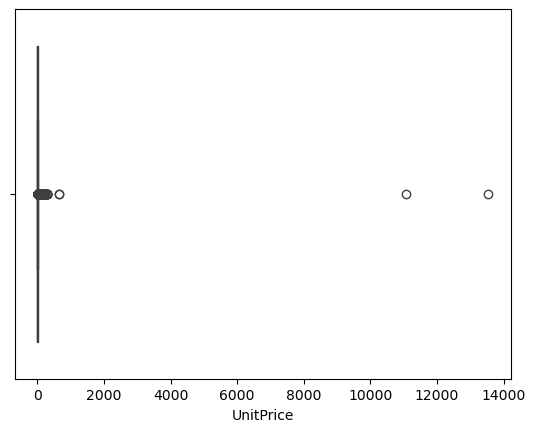

In [33]:
plt.figure()
sns.boxplot(x=df["UnitPrice"])
plt.show()

**we notice they still remain 2 outliers after hundle the descreption so we will drop the manualy**

In [34]:
df=df[df["UnitPrice"] <= 2000]

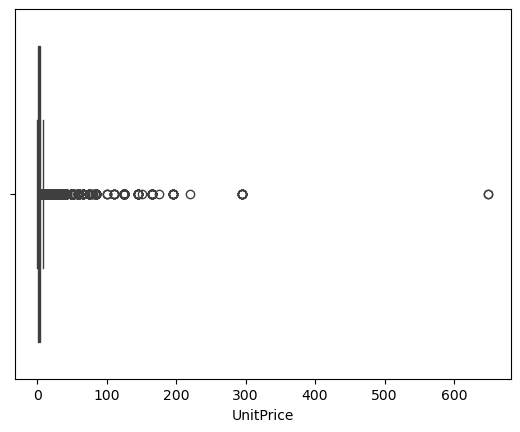

In [35]:
plt.figure()
sns.boxplot(x=df["UnitPrice"])
plt.show()

In [36]:
df["UnitPrice"].describe()

count    522725.000000
mean          3.288389
std           4.475131
min           0.001000
25%           1.250000
50%           2.080000
75%           4.130000
max         649.500000
Name: UnitPrice, dtype: float64

In [37]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60


In [38]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,Revenue
count,522725.000000,522725,522725.000000,522725.000000
mean,10.342660,2011-07-04 16:43:44.013353,3.288389,19.149172
min,1.000000,2010-12-01 08:26:00,0.001000,0.001000
25%,1.000000,2011-03-28 12:13:00,1.250000,3.900000
50%,4.000000,2011-07-20 11:55:00,2.080000,9.900000
75%,12.000000,2011-10-19 11:44:00,4.130000,17.700000
max,4800.000000,2011-12-09 12:50:00,649.500000,38970.000000
std,37.847626,NaN,4.475131,84.654294


In [39]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64

**no the data is clean for our analysis**

In [40]:
df['Year']=df['InvoiceDate'].dt.year
df["Month"] = df["InvoiceDate"].dt.month 
df["Day"] = df["InvoiceDate"].dt.day 
df["Hour"] = df["InvoiceDate"].dt.hour

In [41]:
df[["InvoiceDate", "Year", "Month", "Day", "Hour"]].head()

,InvoiceDate,Year,Month,Day,Hour
0,2010-12-01 08:26:00,2010,12,1,8
1,2010-12-01 08:26:00,2010,12,1,8
2,2010-12-01 08:26:00,2010,12,1,8
3,2010-12-01 08:26:00,2010,12,1,8
4,2010-12-01 08:26:00,2010,12,1,8


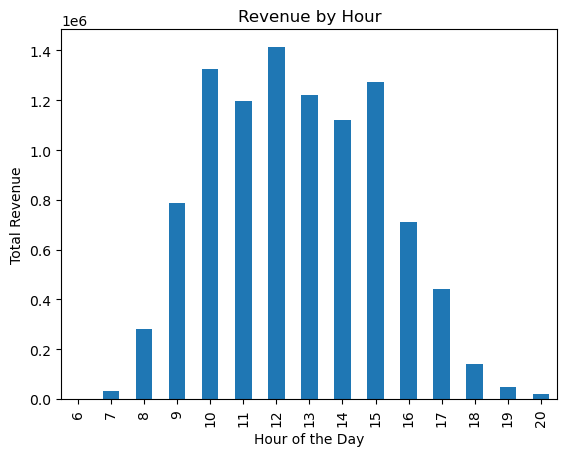

In [42]:
df.groupby ('Hour')['Revenue'].sum().sort_index().plot(kind='bar')
plt.title('Revenue by Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Total Revenue')
plt.show()

**Revenue increases from around 9 AM, peaks around midday (≈12 PM), stays relatively high during business hours, then drops sharply after 5 PM, with almost no activity at night**

In [43]:
df.groupby("Hour")["Revenue"].sum().idxmax()

np.int32(12)

In [44]:
df["Month"].nunique()

12

In [45]:
df.groupby(["Year", "Month"])["Revenue"].sum()

Year  Month
2010  12        776329.950
2011  1         593470.860
      2         508081.540
      3         690811.600
      4         515914.661
      5         740487.330
      6         738233.990
      7         688802.671
      8         724708.160
      9        1029275.382
      10       1104093.970
      11       1453295.980
      12        446244.650
Name: Revenue, dtype: float64

**we will do 2011 month analyse**

In [46]:
df_2011 = df[df["Year"] == 2011].copy()
df_2011["MonthName"] = df_2011["InvoiceDate"].dt.strftime("%b")

In [47]:
df

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Day,Hour
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,1,8
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,1,8
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20,2011,12,9,12
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60,2011,12,9,12
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,9,12
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,9,12


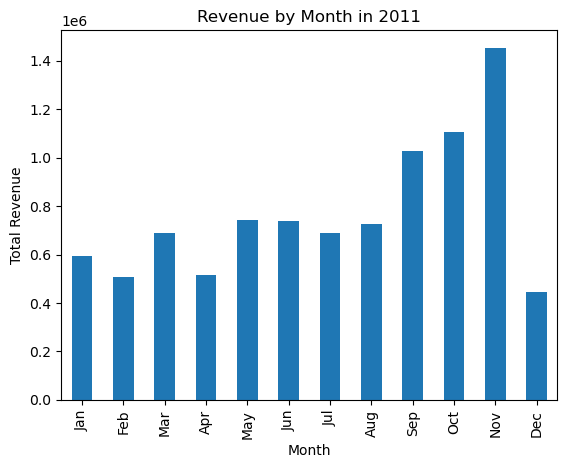

In [48]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
df_2011.groupby('MonthName')['Revenue'].sum().reindex(month_order).plot(kind='bar') 
plt.title('Revenue by Month in 2011')
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.show()

**Revenue peaks in November, with a strong increase starting in September–October, suggesting a seasonal surge toward the end of the year.**

In [49]:
df_2011.groupby("Month")["Revenue"].sum().idxmax()

np.int32(11)

**Revenue peaks in November due to increased purchasing activity driven by events like Black Friday and early holiday (Christmas) preparation, where businesses stock up in advance.**

<h1 style="color:red;">KPI Analysis</h1>

**we will use the revenu as a metric of success**

In [50]:
# 1. Ensure InvoiceDate is a datetime object
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 2. Create a Year-Month string column (e.g., '2010-12', '2011-01')
df['Year_Month'] = df['InvoiceDate'].dt.to_period('M').astype(str)




In [51]:
df.info()

<class 'pandas.DataFrame'>
Index: 522725 entries, 0 to 541908
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    522725 non-null  str           
 1   StockCode    522725 non-null  str           
 2   Description  522725 non-null  str           
 3   Quantity     522725 non-null  int64         
 4   InvoiceDate  522725 non-null  datetime64[us]
 5   UnitPrice    522725 non-null  float64       
 6   CustomerID   522725 non-null  str           
 7   Country      522725 non-null  str           
 8   Revenue      522725 non-null  float64       
 9   Year         522725 non-null  int32         
 10  Month        522725 non-null  int32         
 11  Day          522725 non-null  int32         
 12  Hour         522725 non-null  int32         
 13  Year_Month   522725 non-null  str           
dtypes: datetime64[us](1), float64(2), int32(4), int64(1), str(6)
memory usage: 83.7 MB


In [52]:
#extract data as csv file
df.to_csv('cleaned_data.csv', index=False)

In [53]:
df1=pd.read_csv("cleaned_data.csv")
df1

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Year,Month,Day,Hour,Year_Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010,12,1,8,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010,12,1,8,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010,12,1,8,2010-12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
522720,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680,France,10.20,2011,12,9,12,2011-12
522721,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680,France,12.60,2011,12,9,12,2011-12
522722,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,9,12,2011-12
522723,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680,France,16.60,2011,12,9,12,2011-12


<h2 style=color:blue>RFM ANALYSIS </h2>

In [54]:
df1.info()  

<class 'pandas.DataFrame'>
RangeIndex: 522725 entries, 0 to 522724
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    522725 non-null  int64  
 1   StockCode    522725 non-null  str    
 2   Description  522725 non-null  str    
 3   Quantity     522725 non-null  int64  
 4   InvoiceDate  522725 non-null  str    
 5   UnitPrice    522725 non-null  float64
 6   CustomerID   522725 non-null  str    
 7   Country      522725 non-null  str    
 8   Revenue      522725 non-null  float64
 9   Year         522725 non-null  int64  
 10  Month        522725 non-null  int64  
 11  Day          522725 non-null  int64  
 12  Hour         522725 non-null  int64  
 13  Year_Month   522725 non-null  str    
dtypes: float64(2), int64(6), str(6)
memory usage: 93.8 MB


In [55]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 522725 entries, 0 to 522724
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    522725 non-null  int64  
 1   StockCode    522725 non-null  str    
 2   Description  522725 non-null  str    
 3   Quantity     522725 non-null  int64  
 4   InvoiceDate  522725 non-null  str    
 5   UnitPrice    522725 non-null  float64
 6   CustomerID   522725 non-null  str    
 7   Country      522725 non-null  str    
 8   Revenue      522725 non-null  float64
 9   Year         522725 non-null  int64  
 10  Month        522725 non-null  int64  
 11  Day          522725 non-null  int64  
 12  Hour         522725 non-null  int64  
 13  Year_Month   522725 non-null  str    
dtypes: float64(2), int64(6), str(6)
memory usage: 93.8 MB


In [56]:
#recency

rfm_df = df[df['CustomerID'] != 'Guest'].copy()
rfm_df['Recency'] = (rfm_df['InvoiceDate'].max() - rfm_df['InvoiceDate']).dt.days
# 3. Create Total Spent for the Monetary calculation
rfm_df['Total_Spent'] = rfm_df['Quantity'] * rfm_df['UnitPrice']

# 4. Set our reference date (1 day after the latest purchase)
snapshot_date = rfm_df['InvoiceDate'].max() + pd.Timedelta(days=1)

# 5. Aggregate data per customer
rfm = rfm_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'InvoiceNo': lambda x: x.nunique(),                       # Frequency
    'Total_Spent': 'sum',                                      # Monetary
    'Country': lambda x: x.mode().iloc[0]                      # Most common country
})

# 6. Rename columns for clarity
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'Total_Spent': 'Monetary'
}, inplace=True)

rfm.reset_index(inplace=True)

print(rfm.head())

  CustomerID  Recency  Frequency  Monetary  Country
0      12347        2          7   4310.00  Iceland
1      12348       75          4   1437.24  Finland
2      12349       19          1   1457.55    Italy
3      12350      310          1    294.40   Norway
4      12352       36          7   1385.74   Norway


In [57]:
# Recency: Lower values are better -> labels=[5, 4, 3, 2, 1]
rfm['R_Score'] = pd.qcut(rfm['Recency'], q=5, labels=[5, 4, 3, 2, 1])

# Frequency & Monetary: Higher values are better -> labels=[1, 2, 3, 4, 5]
# We use rank(method='first') to handle ties cleanly if many customers have identical low frequencies
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], q=5, labels=[1, 2, 3, 4, 5])

# Combine scores into a single string identifier
rfm['RFM_Cell'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

print(rfm[['Recency', 'Frequency', 'Monetary', 'RFM_Cell']].head())

   Recency  Frequency  Monetary RFM_Cell
0        2          7   4310.00      555
1       75          4   1437.24      244
2       19          1   1457.55      414
3      310          1    294.40      112
4       36          7   1385.74      354


In [58]:
# Define mapping logic using regex strings based on R and F scores
segs = {
    r'[4-5][4-5][0-5]': 'Champions',
    r'[2-5][3-5][0-5]': 'Loyal Customers',
    r'[3-5][1-2][0-5]': 'Recent / New Buyers',
    r'[2-3][1-2][0-5]': 'About to Sleep',
    r'[1-2][3-5][0-5]': 'Can\'t Lose Them',
    r'[1-2][1-2][0-5]': 'Hibernating / Lost'
}

rfm['Segment'] = rfm['RFM_Cell'].replace(segs, regex=True)

# Let's see the distribution of your customer segments!
print(rfm['Segment'].value_counts())

Segment
Loyal Customers        1267
Champions              1135
Hibernating / Lost      669
Recent / New Buyers     666
About to Sleep          399
Can't Lose Them         198
Name: count, dtype: int64


In [59]:
rfm

,CustomerID,Recency,Frequency,Monetary,Country,R_Score,F_Score,M_Score,RFM_Cell,Segment
0,12347,2,7,4310.00,Iceland,5,5,5,555,Champions
1,12348,75,4,1437.24,Finland,2,4,4,244,Loyal Customers
2,12349,19,1,1457.55,Italy,4,1,4,414,Recent / New Buyers
3,12350,310,1,294.40,Norway,1,1,2,112,Hibernating / Lost
4,12352,36,7,1385.74,Norway,3,5,4,354,Loyal Customers
...,...,...,...,...,...,...,...,...,...,...
4329,18280,278,1,180.60,United Kingdom,1,2,1,121,Hibernating / Lost
4330,18281,181,1,80.82,United Kingdom,1,2,1,121,Hibernating / Lost
4331,18282,8,2,178.05,United Kingdom,5,3,1,531,Loyal Customers
4332,18283,4,16,2039.58,United Kingdom,5,5,5,555,Champions


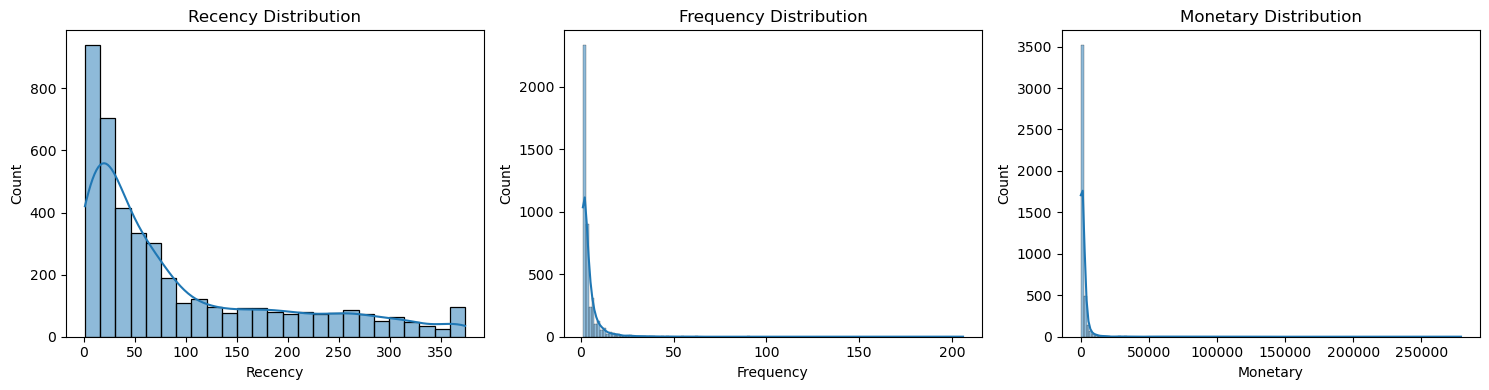

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the plotting area
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Plot histograms for Recency, Frequency, and Monetary
sns.histplot(rfm['Recency'], kde=True, ax=ax[0]).set_title('Recency Distribution')
sns.histplot(rfm['Frequency'], kde=True, ax=ax[1]).set_title('Frequency Distribution')
sns.histplot(rfm['Monetary'], kde=True, ax=ax[2]).set_title('Monetary Distribution')

plt.tight_layout()
plt.show()

 k     inertia  silhouette
 2 6470.291263    0.433049
 3 4853.344380    0.337121
 4 3924.841134    0.337844
 5 3279.233250    0.317335
 6 2838.408144    0.313525
 7 2535.092283    0.309301
 8 2321.993340    0.302450


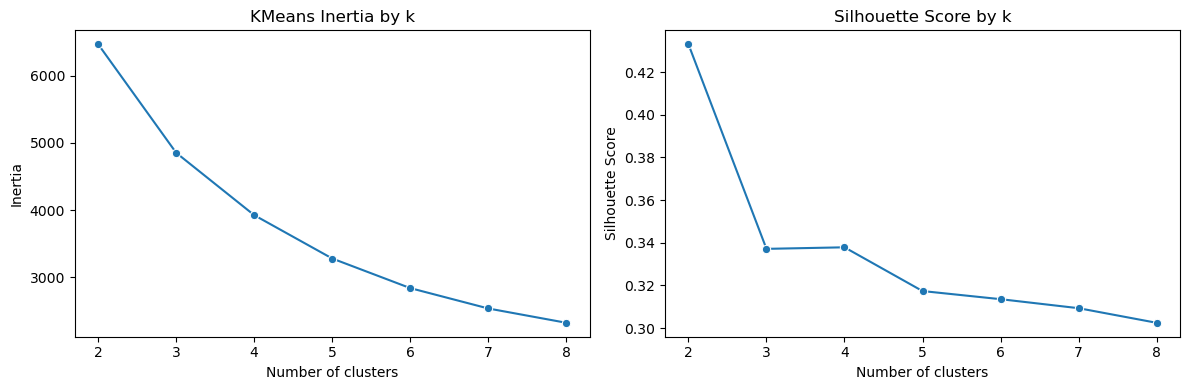


Selected k for RFM segmentation: 5


In [61]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Prepare RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Stabilize skew and align direction: higher is better for all features
rfm_features["Recency"] = -np.log1p(rfm_features["Recency"])
rfm_features["Frequency"] = np.log1p(rfm_features["Frequency"])
rfm_features["Monetary"] = np.log1p(rfm_features["Monetary"])

# Scale features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Evaluate cluster counts from 2 to 8
scores = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    inertia = model.inertia_
    sil = silhouette_score(rfm_scaled, labels)
    scores.append((k, inertia, sil))

scores_df = pd.DataFrame(scores, columns=["k", "inertia", "silhouette"])
print(scores_df.to_string(index=False))

# Plot evaluation metrics
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.lineplot(data=scores_df, x="k", y="inertia", marker="o")
plt.title("KMeans Inertia by k")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")

plt.subplot(1, 2, 2)
sns.lineplot(data=scores_df, x="k", y="silhouette", marker="o")
plt.title("Silhouette Score by k")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.show()

# Use five clusters for the RFM segmentation
best_k = 5
print(f"\nSelected k for RFM segmentation: {best_k}")

In [62]:
# Fit KMeans with the selected k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["KMeansCluster"] = kmeans.fit_predict(rfm_scaled)

# Profile clusters in original RFM scale
cluster_profile = rfm.groupby("KMeansCluster")[["Recency", "Frequency", "Monetary"]].mean().round(1)
cluster_profile["Count"] = rfm.groupby("KMeansCluster").size()
cluster_profile = cluster_profile.sort_values(["Monetary", "Frequency"], ascending=False)

print("Cluster Profiles (sorted by Monetary then Frequency):")
print(cluster_profile)

Cluster Profiles (sorted by Monetary then Frequency):
               Recency  Frequency  Monetary  Count
KMeansCluster                                     
3                 11.4       21.4   13778.3    316
1                 18.6        5.9    2208.9    952
4                103.7        3.1    1354.6   1028
2                 26.9        1.6     385.1    835
0                209.0        1.2     272.3   1203


In [63]:
# Label clusters from best to worst based on the sorted profile
cluster_order = cluster_profile.index.tolist()
label_names = [
    "Champions",
    "Loyal Customers",
    "Potential Growth",
    "Needs Attention",
    "At Risk",
    "Low Value",
    "New Opportunity"
]

cluster_labels = {
    cluster_order[i]: label_names[i] for i in range(min(len(cluster_order), len(label_names)))
}

rfm["KMeansSegment"] = rfm["KMeansCluster"].map(cluster_labels)

print("\nSegment Distribution:")
print(rfm["KMeansSegment"].value_counts())
print("\nSegment percentages:")
print(rfm["KMeansSegment"].value_counts(normalize=True).round(3) * 100)


Segment Distribution:
KMeansSegment
At Risk             1203
Potential Growth    1028
Loyal Customers      952
Needs Attention      835
Champions            316
Name: count, dtype: int64

Segment percentages:
KMeansSegment
At Risk             27.8
Potential Growth    23.7
Loyal Customers     22.0
Needs Attention     19.3
Champions            7.3
Name: proportion, dtype: float64


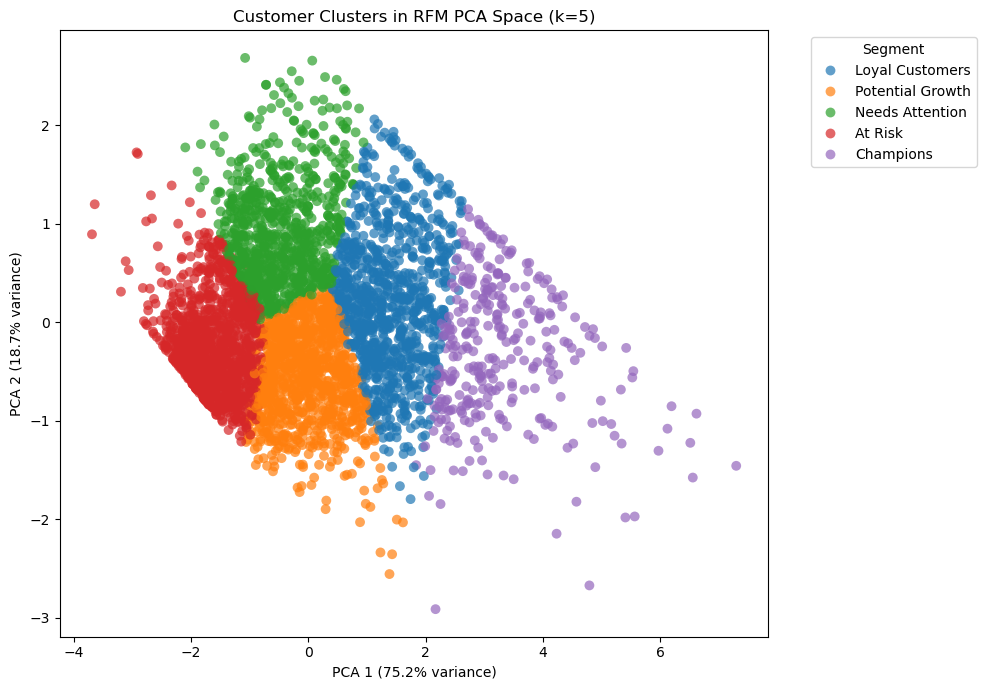


Detailed Segment Summary:
                 Recency                 Frequency                Monetary  \
                   count   mean min  max     count  mean min  max    count   
KMeansSegment                                                                
At Risk             1203  209.0  50  374      1203   1.2   1    6     1203   
Champions            316   11.4   1  372       316  21.4   6  206      316   
Loyal Customers      952   18.6   1  114       952   5.9   1   14      952   
Needs Attention      835   26.9   1   70       835   1.6   1    7      835   
Potential Growth    1028  103.7  21  372      1028   3.1   1   12     1028   

                                             
                     mean     min       max  
KMeansSegment                                
At Risk             272.3     2.9    1141.2  
Champions         13778.3  1296.4  279138.0  
Loyal Customers    2208.9   306.7   13219.7  
Needs Attention     385.1    20.8    1457.6  
Potential Growth   1354.6 

In [64]:
# Plot clusters in 2D PCA space
pca = PCA(n_components=5, random_state=42)
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(rfm_scaled)
rfm[["Cluster_PCA1", "Cluster_PCA2"]] = pca_result

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=rfm,
    x="Cluster_PCA1",
    y="Cluster_PCA2",
    hue="KMeansSegment",
    palette="tab10",
    alpha=0.7,
    edgecolor="none",
    s=50
)
plt.title(f"Customer Clusters in RFM PCA Space (k={best_k})")
plt.xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend(title="Segment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Show segment summary with counts and averages
print("\nDetailed Segment Summary:")
segment_summary = rfm.groupby("KMeansSegment")[["Recency", "Frequency", "Monetary"]].agg(
    ["count", "mean", "min", "max"]
).round(1)
print(segment_summary)

In [65]:
# Compare KMeans segments with original RFM score segments
comparison = pd.crosstab(
    rfm["Segment"], 
    rfm["KMeansSegment"], 
    margins=True
)
print("Cross-tabulation: RFM Scores vs KMeans Segments")
print(comparison)

# Show average RFM metrics by KMeans segment
print("\n\nAverage RFM Metrics by KMeans Segment:")
rfm_by_segment = rfm.groupby("KMeansSegment")[["Recency", "Frequency", "Monetary"]].mean().round(1)
rfm_by_segment = rfm_by_segment.sort_values("Monetary", ascending=False)
print(rfm_by_segment)

Cross-tabulation: RFM Scores vs KMeans Segments
KMeansSegment        At Risk  Champions  Loyal Customers  Needs Attention  \
Segment                                                                     
About to Sleep           312          0                0                0   
Can't Lose Them           88          1                0                0   
Champions                  0        303              749               55   
Hibernating / Lost       631          0                0                0   
Loyal Customers           75         12              192              291   
Recent / New Buyers       97          0               11              489   
All                     1203        316              952              835   

KMeansSegment        Potential Growth   All  
Segment                                      
About to Sleep                     87   399  
Can't Lose Them                   109   198  
Champions                          28  1135  
Hibernating / Lost          

In [66]:
#rfm to csv extract 


rfm.to_csv('rfm.csv', index=False)




In [67]:
df.info()

<class 'pandas.DataFrame'>
Index: 522725 entries, 0 to 541908
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    522725 non-null  str           
 1   StockCode    522725 non-null  str           
 2   Description  522725 non-null  str           
 3   Quantity     522725 non-null  int64         
 4   InvoiceDate  522725 non-null  datetime64[us]
 5   UnitPrice    522725 non-null  float64       
 6   CustomerID   522725 non-null  str           
 7   Country      522725 non-null  str           
 8   Revenue      522725 non-null  float64       
 9   Year         522725 non-null  int32         
 10  Month        522725 non-null  int32         
 11  Day          522725 non-null  int32         
 12  Hour         522725 non-null  int32         
 13  Year_Month   522725 non-null  str           
dtypes: datetime64[us](1), float64(2), int32(4), int64(1), str(6)
memory usage: 83.7 MB


In [68]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 522725 entries, 0 to 522724
Data columns (total 14 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    522725 non-null  int64  
 1   StockCode    522725 non-null  str    
 2   Description  522725 non-null  str    
 3   Quantity     522725 non-null  int64  
 4   InvoiceDate  522725 non-null  str    
 5   UnitPrice    522725 non-null  float64
 6   CustomerID   522725 non-null  str    
 7   Country      522725 non-null  str    
 8   Revenue      522725 non-null  float64
 9   Year         522725 non-null  int64  
 10  Month        522725 non-null  int64  
 11  Day          522725 non-null  int64  
 12  Hour         522725 non-null  int64  
 13  Year_Month   522725 non-null  str    
dtypes: float64(2), int64(6), str(6)
memory usage: 93.8 MB
